In [10]:
%pip install numpy pandas scikit-learn prettytable astropy

Note: you may need to restart the kernel to use updated packages.


In [11]:
# Import Libraries

import numpy as np
import pandas as pd
import pickle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.metrics import accuracy_score

from prettytable import PrettyTable   
from astropy.table import Table, Column

In [12]:
# Load Sample Data

''' 
*---------------------- LOAD_SAMPLE_DATA ------------------------*
|     Function: read_csv()                                       |
|             Purpose: Read a dataset in CSV file format         |
|     Arguments:                                                 |
|             path: Path to dataset file                         |
|             dataset: Dataset file name                         |
|     Return:                                                    |
|             dataset: Dataset in DataFrame format               |
*----------------------------------------------------------------*
'''
 
sample_data = pd.read_csv("sample-data.csv")

print("\n\nSample Data:")
print("============\n")
pd.set_option("display.max_rows", None, "display.max_columns", None)
print(sample_data)



Sample Data:

    PClass  Gender Sibling     Embarked Survived
0    Third    Male     One  Southampton       No
1   Second  Female    Zero  Southampton      Yes
2    Third    Male    Zero  Southampton       No
3    Third  Female   Three  Southampton      Yes
4    Third    Male    Zero   Queenstown       No
5    First  Female   Three  Southampton      Yes
6    Third    Male    Zero  Southampton       No
7    Third    Male    Zero  Southampton      Yes
8    First    Male    Zero  Southampton       No
9   Second    Male    Zero  Southampton      Yes
10   Third    Male     One   Queenstown       No
11   First    Male    Zero    Cherbourg      Yes
12   First    Male    Zero    Cherbourg       No
13  Second  Female    Zero  Southampton      Yes
14  Second    Male    Zero  Southampton       No
15   Third    Male     One    Cherbourg      Yes
16   Third    Male     Two    Cherbourg       No
17   Third    Male    Zero  Southampton      Yes
18   Third    Male    Zero  Southampton       No
19  

In [13]:
# Understand Sample Data

print("\n\nAttributes in Sample Data:")
print("==========================\n")

print(sample_data.columns)

print("\n\nNumber of Instances in Sample Data:",sample_data["PClass"].count())
print("========================================\n")  




Attributes in Sample Data:

Index(['PClass', 'Gender', 'Sibling', 'Embarked', 'Survived'], dtype='object')


Number of Instances in Sample Data: 100



In [14]:
# Train the Label Encoder

''' 
*------------------ TRAIN_LABEL_ENCODER --------------------*
|        Function: Fit()                                    |
|              Purpose: Fit or Train the Label Encoder      |
|        Arguments:                                         |
|               Labels: Target Values                       |
|        Return:                                            |
|               Instance: Returns an instance of self       |
*-----------------------------------------------------------*
''' 

# Labels

pclass = pd.DataFrame({"Pclass":["First","Second","Third"]})
gender = pd.DataFrame({"Gender":["Male","Female"]})
sibling = pd.DataFrame({"Sibling":["Zero","One","Two","Three"]})
embarked = pd.DataFrame({"Embarked":["Southampton","Cherbourg","Queenstown"]})
survived = pd.DataFrame({"Survived":["Yes","No"]})

# Initialize the Label Encoders 

pclass_label_encoder = LabelEncoder()
gender_label_encoder = LabelEncoder()
sibling_label_encoder = LabelEncoder()
embarked_label_encoder = LabelEncoder()
survived_label_encoder = LabelEncoder()

# Train the Label Encoders

pclass_label_encoder.fit(np.ravel(pclass))
gender_label_encoder.fit(np.ravel(gender))
sibling_label_encoder.fit(np.ravel(sibling))
embarked_label_encoder.fit(np.ravel(embarked))
survived_label_encoder.fit(np.ravel(survived))

import pickle

# Save trained label encoders
with open("pclass_encoder.pkl", "wb") as f:
    pickle.dump(pclass_label_encoder, f)

with open("gender_encoder.pkl", "wb") as f:
    pickle.dump(gender_label_encoder, f)

with open("sibling_encoder.pkl", "wb") as f:
    pickle.dump(sibling_label_encoder, f)

with open("embarked_encoder.pkl", "wb") as f:
    pickle.dump(embarked_label_encoder, f)

with open("survived_encoder.pkl", "wb") as f:
    pickle.dump(survived_label_encoder, f)


In [16]:
# Label Encoding of the Output

''' 
*------------------ LABEL_ENCODE_OUTPUT --------------------*
|        Function: Transform()                              |
|              Purpose: Transform Input (Categorical)       |
|                       into Numerical Representation       |
|        Arguments:                                         |
|              Attribute: Target values                     |
|        Return:                                            |
|              Attribute: Numerical Representation          |
*-----------------------------------------------------------*
'''

sample_data_encoded_output = sample_data.copy()
original_sample_data = sample_data.copy()

# Transform Output of into Numerical Representation

print("\n\nSurvived Attribute After Label Encoding:")
print("========================================\n")
sample_data["encoded_survived"] = survived_label_encoder.transform(sample_data['Survived'])
print(sample_data[["Survived", "encoded_survived"]])

# Print Original and Encoded Ouput Sample Data

sample_data_encoded_output[['PClass', 'Gender', 'Sibling', 'Embarked', 'Survived']] = sample_data[['PClass', 'Gender', 'Sibling', 'Embarked', 'encoded_survived']]
pd.set_option("display.max_rows", None, "display.max_columns", None)
print("\n\nOriginal Sample Data:")
print("=====================\n")
pd.set_option("display.max_rows", None, "display.max_columns", None)
print(original_sample_data)
print("\n\nSample Data after Label Encoding of Output:")
print("===========================================\n")
pd.set_option("display.max_rows", None, "display.max_columns", None)
print(sample_data_encoded_output)

# Save the Transformed Features into CSV File 

sample_data_encoded_output.to_csv(r'sample-data-encoded-output.csv', index = False, header = True)



Survived Attribute After Label Encoding:

   Survived  encoded_survived
0        No                 0
1       Yes                 1
2        No                 0
3       Yes                 1
4        No                 0
5       Yes                 1
6        No                 0
7       Yes                 1
8        No                 0
9       Yes                 1
10       No                 0
11      Yes                 1
12       No                 0
13      Yes                 1
14       No                 0
15      Yes                 1
16       No                 0
17      Yes                 1
18       No                 0
19      Yes                 1
20       No                 0
21      Yes                 1
22       No                 0
23      Yes                 1
24       No                 0
25      Yes                 1
26       No                 0
27      Yes                 1
28       No                 0
29      Yes                 1
30       No               

In [17]:
# Label Encoding of the Input

''' 
*------------------- LABEL_ENCODE_INPUT --------------------*
|        Function: Transform()                              |
|              Purpose: Transform Input (Categorical)       |
|                          into Numerical Representation    |
|        Arguments:                                         |
|              Attribute: Target values                     |
|        Return:                                            |
|              Attribute: Numerical Representation          |
*-----------------------------------------------------------*
'''

sample_data_encoded = sample_data_encoded_output.copy()
sample_data_encoded_output_orignal = sample_data_encoded_output.copy()

# Transform Input Attributes into Numerical Representation

print("\n\nPClass Attribute After Label Encoding:")
print("======================================\n")
sample_data_encoded_output["encoded_pclass"] = pclass_label_encoder.transform(sample_data_encoded_output['PClass'])
pd.set_option("display.max_rows", None, "display.max_columns", None)
print(sample_data_encoded_output[["PClass", "encoded_pclass"]])

print("\n\nGender Attribute After Label Encoding:")
print("======================================\n")
sample_data_encoded_output["encoded_gender"] = gender_label_encoder.transform(sample_data_encoded_output['Gender'])
pd.set_option("display.max_rows", None, "display.max_columns", None)
print(sample_data_encoded_output[["Gender", "encoded_gender"]])

print("\n\nSibling Attribute After Label Encoding:")
print("=======================================\n")
sample_data_encoded_output["encoded_sibling"] = sibling_label_encoder.transform(sample_data_encoded_output['Sibling'])
pd.set_option("display.max_rows", None, "display.max_columns", None)
print(sample_data_encoded_output[["Sibling", "encoded_sibling"]])

print("\n\nEmbarked Attribute After Label Encoding:")
print("========================================\n")
sample_data_encoded_output["encoded_embarked"] = embarked_label_encoder.transform(sample_data_encoded_output['Embarked'])
pd.set_option("display.max_rows", None, "display.max_columns", None)
print(sample_data_encoded_output[["Embarked", "encoded_embarked"]])

# Print Original and Encoded Sample Data

sample_data_encoded[['PClass', 'Gender', 'Sibling', 'Embarked', 'Survived']] = sample_data_encoded_output[['encoded_pclass', 'encoded_gender', 'encoded_sibling', 'encoded_embarked', 'Survived']]
print("\n\nOriginal Sample Data:")
print("=====================\n")
pd.set_option("display.max_rows", None, "display.max_columns", None)
print(original_sample_data)
print("\n\nSample Data after Label Encoding:")
print("=================================\n")
pd.set_option("display.max_rows", None, "display.max_columns", None)
print(sample_data_encoded)

# Save the Transformed Features into CSV File 

sample_data_encoded.to_csv(r'sample-data-encoded.csv', index = False, header = True)



PClass Attribute After Label Encoding:

    PClass  encoded_pclass
0    Third               2
1   Second               1
2    Third               2
3    Third               2
4    Third               2
5    First               0
6    Third               2
7    Third               2
8    First               0
9   Second               1
10   Third               2
11   First               0
12   First               0
13  Second               1
14  Second               1
15   Third               2
16   Third               2
17   Third               2
18   Third               2
19   Third               2
20   Third               2
21   First               0
22   First               0
23  Second               1
24   Third               2
25   Third               2
26   Third               2
27   Third               2
28   Third               2
29   Third               2
30   Third               2
31   First               0
32   Third               2
33   First               0
34   First   

In [18]:
# Splitting Sample Data into Training Data and Testing Data

''' 
*------------------- SPLIT_SAMPLE_DATA ---------------------*
|        Function: train_test_split()                       |
|              Purpose: Split arrays or matrices into       |
|                       random train and test subsets       |
|        Arguments:                                         |
|              arrays: sequence of indexables               |
|              test_size: float or int                      |
|        Return:                                            |
|              splitting: list                              |
*-----------------------------------------------------------*
'''

training_data_encoded, testing_data_encoded = train_test_split( sample_data_encoded , test_size=0.2 , random_state=42, shuffle = False)

# # Save the Training and Testing Data into CSV File 

# training_data_encoded.to_csv(r'training-data-encoded.csv', index = False, header = True)
# testing_data_encoded.to_csv(r'testing-data-encoded.csv', index = False, header = True)

# # print Training and Testing Data

# print("\n\nTraining Data:")
# print("==============\n")
# pd.set_option("display.max_rows", None, "display.max_columns", None)
# print(training_data_encoded)
# print("\n\nTesting Data:")
# print("==============\n")
# pd.set_option("display.max_rows", None, "display.max_columns", None)
# print(testing_data_encoded)

print("\n\nInputs Vectors (Feature Vectors) of Training Data:")
print("==================================================\n")

# Possible names for the original/encoded target columns (add other variants if you use them)
target_candidates = ["Survived", "Survived_encoded", "encoded_survived"]

# Determine which target column to use as the label (prefer encoded names first)
label_col = None
for name in ("Survived_encoded", "encoded_survived", "Survived"):
    if name in training_data_encoded.columns:
        label_col = name
        break

# Build a list of exactly two columns to drop:
# - If we found an encoded label (Survived_encoded / encoded_survived) drop both that and 'Survived' if present
# - If only 'Survived' exists, drop it (and any other explicit variant found)
cols_to_drop = []
if label_col:
    cols_to_drop.append(label_col)
# Also try to drop the plain 'Survived' column (if it's not already included)
if "Survived" in training_data_encoded.columns and "Survived" not in cols_to_drop:
    cols_to_drop.append("Survived")

# If you want to strictly ensure exactly two columns are dropped but only one was found, you can extend this list
# with any other known variant or simply rely on errors='ignore' below.
input_vector_train = training_data_encoded.drop(columns=cols_to_drop, errors='ignore')

print(f"Dropped columns: {cols_to_drop}")
print(input_vector_train)

print("\n\nOutputs/Labels of Training Data:")
print("================================\n")
if label_col:
    output_label_train = training_data_encoded[label_col]
else:
    raise KeyError("No target column found. Expected one of: " + ", ".join(target_candidates))

print(output_label_train)




Inputs Vectors (Feature Vectors) of Training Data:

Dropped columns: ['Survived']
    PClass  Gender  Sibling  Embarked
0        2       1        0         2
1        1       0        3         2
2        2       1        3         2
3        2       0        1         2
4        2       1        3         1
5        0       0        1         2
6        2       1        3         2
7        2       1        3         2
8        0       1        3         2
9        1       1        3         2
10       2       1        0         1
11       0       1        3         0
12       0       1        3         0
13       1       0        3         2
14       1       1        3         2
15       2       1        0         0
16       2       1        2         0
17       2       1        3         2
18       2       1        3         2
19       2       0        0         0
20       2       1        3         0
21       0       0        3         2
22       0       1        3         0
23  

In [19]:
# Splitting Input Vectors and Outputs / Labels of Training Data

'''
*---------------- SPLIT_INPUT_VECTORS_AND_LABELS --------------*
|        Function: iloc()                                      |
|            Purpose: Splitting Input Vector and Labels        |
|        Arguments:                                            |
|            Attribute: Name or Location Attribute to Split    |
|        Return:                                               |
|            Attribute: Split Attributes                       |
*--------------------------------------------------------------*
'''

print("\n\nInputs Vectors (Feature Vectors) of Training Data:")
print("==================================================\n")
# input_vector_train = training_data_encoded.iloc[: , :-1]
input_vector_train = training_data_encoded.drop(columns=["Survived", "encoded_survived"], errors='ignore')

print(input_vector_train)

print("\n\nOutputs/Labels of Training Data:")
print("================================\n")
print("  Survived")
output_label_train = training_data_encoded.iloc[: ,-1]
print(output_label_train)



Inputs Vectors (Feature Vectors) of Training Data:

    PClass  Gender  Sibling  Embarked
0        2       1        0         2
1        1       0        3         2
2        2       1        3         2
3        2       0        1         2
4        2       1        3         1
5        0       0        1         2
6        2       1        3         2
7        2       1        3         2
8        0       1        3         2
9        1       1        3         2
10       2       1        0         1
11       0       1        3         0
12       0       1        3         0
13       1       0        3         2
14       1       1        3         2
15       2       1        0         0
16       2       1        2         0
17       2       1        3         2
18       2       1        3         2
19       2       0        0         0
20       2       1        3         0
21       0       0        3         2
22       0       1        3         0
23       1       0        3       

In [20]:
# Train the Support Vector Classifier

''' 
*--------------- TRAIN_SUPPORT_VECTOR_CLASSIFIER ------------------*
|       Function: svm.SVC()                                        |
|           Purpose: Train the Algorithm on Training Data          |
|       Arguments:                                                 |
|           Training Data: Provide Training Data to the Model      |
|       Return:                                                    |
|           Parameter: Model return the Training Parameters        |
*------------------------------------------------------------------*
'''

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")
print("\nParameters and their values:")
print("============================\n")
svc_model = svm.SVC(gamma='auto',random_state=0)
svc_model.fit(input_vector_train,np.ravel(output_label_train))
print(svc_model)



Training the Support Vector Classifier on Training Data


Parameters and their values:

SVC(gamma='auto', random_state=0)


In [21]:
# Save the Trained Model

''' 
*--------------------- SAVE_THE_TRAINED_MODEL ---------------------*
|        Function: dump()                                          |
|             Purpose: Save the Trained Model on your Hard Disk    |
|        Arguments:                                                |
|             Model: Model Objects                                 |
|        Return:                                                   |
|             File: Trained Model will be Saved on Hard Disk       |
*------------------------------------------------------------------* 
'''

# Save the Model in a Pkl File

pickle.dump(svc_model, open('svc_trained_model.pkl', 'wb'))

In [22]:
# Splitting Input Vectors and Outputs/Labels of Testing Data

'''
*---------------- SPLIT_INPUT_VECTORS_AND_LABELS --------------*
|        Function: iloc()                                      |
|            Purpose: Splitting Input Vector and Labels        |
|        Arguments:                                            |
|            Attribute: Name or Location Attribute to Split    |
|        Return:                                               |
|            Attribute: Split Attributes                       |
*--------------------------------------------------------------*
'''

print("\n\nInputs Vectors (Feature Vectors) of Testing Data:")
print("=================================================\n")
# input_vector_test = testing_data_encoded.iloc[: , :-1]
input_vector_test = testing_data_encoded.drop(columns=["Survived", "encoded_survived"], errors='ignore')
print(input_vector_test)

print("\n\nOutputs/Labels of Testing Data:")
print("==============================\n")
print("  Survived")
output_label_test = testing_data_encoded.iloc[: ,-1]
print(output_label_test)



Inputs Vectors (Feature Vectors) of Testing Data:

    PClass  Gender  Sibling  Embarked
80       2       1        2         2
81       2       0        3         2
82       2       1        3         2
83       0       1        0         2
84       1       1        3         2
85       2       0        0         1
86       1       1        3         2
87       0       0        0         2
88       2       1        3         2
89       1       0        3         2
90       1       1        3         2
91       1       0        3         2
92       2       1        3         0
93       0       1        0         2
94       0       1        0         2
95       2       1        0         0
96       2       1        0         1
97       2       1        0         2
98       1       1        0         2
99       2       1        0         2


Outputs/Labels of Testing Data:

  Survived
80    0
81    1
82    0
83    1
84    0
85    1
86    0
87    1
88    0
89    1
90    0
91    1
92    0

In [23]:
# Load the Saved Model

''' 
*------------------- LOAD_SAVED_MODEL --------------------------*
|         Function: load()                                      |
|               Purpose: Method to Load Previously Saved Model  |
|         Arguments:                                            |
|               Model: Trained Model                            |
|         Return:                                               |
|               File: Saved Model will be Loaded in Memory      |
*---------------------------------------------------------------*
'''

# Load the Saved Model

model = pickle.load(open('svc_trained_model.pkl', 'rb'))

In [24]:
# Evaluate the Machine Learning Model

''' 
*--------------------- EVALUATE_MACHINE_LEARNING_MODEL ----------------------*
|       Function: Predict()                                                  |
|             Purpose: Make a Prediction using Algorithm on Test Data        |
|       Arguments:                                                           |
|            Testing Data: Provide Test data to the Trained Model            |
|       Return:                                                              |
|            Predictions: Model return Predictions                           |
*----------------------------------------------------------------------------* 
'''

# Provide Test data to the Trained Model
print(input_vector_test)
model_predictions = model.predict(input_vector_test)
testing_data_encoded.copy(deep=True)
pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions

# Save the Predictions into CSV File

testing_data_encoded.to_csv(r'model-predictions.csv', index = False, header = True)

model_predictions = testing_data_encoded 
print("\n\nPredictions Returned by svc_trained_model:")
print("==========================================\n")
print(model_predictions)

    PClass  Gender  Sibling  Embarked
80       2       1        2         2
81       2       0        3         2
82       2       1        3         2
83       0       1        0         2
84       1       1        3         2
85       2       0        0         1
86       1       1        3         2
87       0       0        0         2
88       2       1        3         2
89       1       0        3         2
90       1       1        3         2
91       1       0        3         2
92       2       1        3         0
93       0       1        0         2
94       0       1        0         2
95       2       1        0         0
96       2       1        0         1
97       2       1        0         2
98       1       1        0         2
99       2       1        0         2


Predictions Returned by svc_trained_model:

    PClass  Gender  Sibling  Embarked  Survived  Predictions
80       2       1        2         2         0            0
81       2       0        3       

In [25]:
# Calculate the Accuracy Score

''' 
/*------------------------ CALCULATE_ACCURACY_SCORE -------------------*
|          Function: accuracy_score()                                  |
|                Purpose: Evaluate the algorithm on Testing data       |
|          Arguments:                                                  |
|                Prediction: Predicted values                          |
|                Label: Actual values                                  |
|          Return:                                                     |
|                Accuracy: Accuracy Score                              |
*----------------------------------------------------------------------*
'''

# Calculate the Accuracy

model_accuracy_score = accuracy_score(model_predictions["Survived"],model_predictions["Predictions"])

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score,2))



Accuracy Score:

0.8


In [26]:
sibling_map = {"Zero": 0, "One": 1, "Two": 2, "Three": 3}

ex_data = original_sample_data.copy()
ex_data["FamilySize"] = ex_data["Sibling"].map(sibling_map) + 1
ex_data["IsAlone"] = (ex_data["FamilySize"] == 1).astype(int)

print(ex_data[["Sibling", "FamilySize", "IsAlone"]].head(10))

  Sibling  FamilySize  IsAlone
0     One           2        0
1    Zero           1        1
2    Zero           1        1
3   Three           4        0
4    Zero           1        1
5   Three           4        0
6    Zero           1        1
7    Zero           1        1
8    Zero           1        1
9    Zero           1        1


In [27]:
ex_data["PClass"] = pclass_label_encoder.transform(ex_data["PClass"])
ex_data["Gender"] = gender_label_encoder.transform(ex_data["Gender"])
ex_data["Sibling"] = sibling_label_encoder.transform(ex_data["Sibling"])
ex_data["Embarked"] = embarked_label_encoder.transform(ex_data["Embarked"])
ex_data["Survived"] = survived_label_encoder.transform(ex_data["Survived"])

base_features = ["PClass", "Gender", "Sibling", "Embarked"]
extra_features = base_features + ["FamilySize", "IsAlone"]

train_df, test_df = train_test_split(ex_data, test_size=0.2, random_state=42, shuffle=False)
y_train, y_test = train_df["Survived"], test_df["Survived"]

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
}

rows = []
for name, mdl in models.items():
    mdl.fit(train_df[base_features], y_train)
    acc_without = accuracy_score(y_test, mdl.predict(test_df[base_features]))

    mdl.fit(train_df[extra_features], y_train)
    acc_with = accuracy_score(y_test, mdl.predict(test_df[extra_features]))

    rows.append([name, round(acc_without, 3), round(acc_with, 3), round(acc_with - acc_without, 3)])

result = pd.DataFrame(rows, columns=["Model", "Without", "With", "Delta"])
print(result)

                 Model  Without  With  Delta
0  Logistic Regression     0.75  0.75    0.0
1        Decision Tree     0.80  0.80    0.0
2        Random Forest     0.80  0.80    0.0


In [29]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

auc_scores = {}
for name, mdl in models.items():
    mdl.fit(train_df[extra_features], y_train)
    prob = mdl.predict_proba(test_df[extra_features])[:, 1]
    auc_scores[name] = roc_auc_score(y_test, prob)

print(auc_scores)

best_name = max(auc_scores, key=auc_scores.get)
best_model = models[best_name]
print("Best model:", best_name)

{'Logistic Regression': np.float64(0.6499999999999999), 'Decision Tree': np.float64(0.7), 'Random Forest': np.float64(0.6699999999999999)}
Best model: Decision Tree


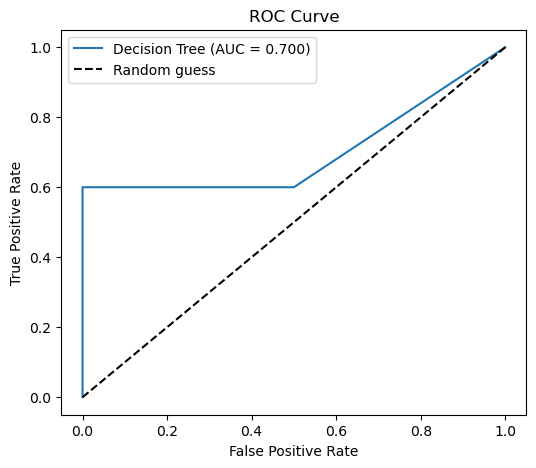

AUC: 0.7


In [30]:
y_prob = best_model.predict_proba(test_df[extra_features])[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

os.makedirs("figures", exist_ok=True)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"{best_name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.savefig("figures/roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

print("AUC:", round(auc, 3))

In [31]:
from sklearn.model_selection import cross_val_score

X_all = ex_data[extra_features]
y_all = ex_data["Survived"]

cv_rows = []
for name, mdl in models.items():
    cv = cross_val_score(mdl, X_all, y_all, cv=5, scoring="accuracy")
    cv_rows.append([name, round(cv.mean(), 3), round(cv.std(), 3)])

cv_result = pd.DataFrame(cv_rows, columns=["Model", "CV Mean", "CV Std"])
print(cv_result)

                 Model  CV Mean  CV Std
0  Logistic Regression     0.68   0.040
1        Decision Tree     0.68   0.081
2        Random Forest     0.67   0.081


In [32]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

models["KNN"] = KNeighborsClassifier()
models["SVC"] = SVC(gamma="auto", random_state=0)

In [33]:
rows = []
for name, mdl in models.items():
    mdl.fit(train_df[base_features], y_train)
    acc_without = accuracy_score(y_test, mdl.predict(test_df[base_features]))

    mdl.fit(train_df[extra_features], y_train)
    acc_with = accuracy_score(y_test, mdl.predict(test_df[extra_features]))

    rows.append([name, round(acc_without, 3), round(acc_with, 3), round(acc_with - acc_without, 3)])

result = pd.DataFrame(rows, columns=["Model", "Without", "With", "Delta"])
print(result)

                 Model  Without  With  Delta
0  Logistic Regression     0.75  0.75   0.00
1        Decision Tree     0.80  0.80   0.00
2        Random Forest     0.80  0.80   0.00
3                  KNN     0.80  0.85   0.05
4                  SVC     0.80  0.80   0.00


In [34]:
cv_rows = []
for name, mdl in models.items():
    cv = cross_val_score(mdl, X_all, y_all, cv=5, scoring="accuracy")
    cv_rows.append([name, round(cv.mean(), 3), round(cv.std(), 3)])

cv_result = pd.DataFrame(cv_rows, columns=["Model", "CV Mean", "CV Std"])
print(cv_result)

                 Model  CV Mean  CV Std
0  Logistic Regression     0.68   0.040
1        Decision Tree     0.68   0.081
2        Random Forest     0.67   0.081
3                  KNN     0.65   0.105
4                  SVC     0.69   0.066


In [35]:
summary = result.merge(cv_result, on="Model")
summary = summary.sort_values("CV Mean", ascending=False).reset_index(drop=True)
print(summary)

                 Model  Without  With  Delta  CV Mean  CV Std
0                  SVC     0.80  0.80   0.00     0.69   0.066
1  Logistic Regression     0.75  0.75   0.00     0.68   0.040
2        Decision Tree     0.80  0.80   0.00     0.68   0.081
3        Random Forest     0.80  0.80   0.00     0.67   0.081
4                  KNN     0.80  0.85   0.05     0.65   0.105


In [ ]:
## Exercise 5: Summary

| Model | Test Acc | CV Mean | CV Std |
|---|---|---|---|
| SVC | 0.80 | 0.69 | 0.066 |
| Logistic Regression | 0.75 | 0.68 | 0.040 |
| Decision Tree | 0.80 | 0.68 | 0.081 |
| Random Forest | 0.80 | 0.67 | 0.081 |
| KNN | 0.85 | 0.65 | 0.105 |

- FamilySize and IsAlone did not improve accuracy because they are derived from Sibling.
- KNN's high test accuracy was luck (20-row test set). It has the lowest CV mean and highest variance.
- Logistic Regression is the most stable (Std 0.040).

**Deploy: SVC.** It has the highest CV mean (0.69) with low variance (0.066).

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

# Raw text data, not the encoded version
raw_data = original_sample_data.copy()
X_raw = raw_data[["PClass", "Gender", "Sibling", "Embarked"]]
y_raw = (raw_data["Survived"] == "Yes").astype(int)

cat_cols = ["PClass", "Gender", "Sibling", "Embarked"]

preprocess = ColumnTransformer([
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ("scaler", StandardScaler()),
    ]), cat_cols)
])

pipe = Pipeline([
    ("prep", preprocess),
    ("model", SVC(gamma="auto", random_state=0)),
])

In [37]:
from sklearn.model_selection import cross_val_score

pipe_cv = cross_val_score(pipe, X_raw, y_raw, cv=5, scoring="accuracy")
print("Pipeline CV scores:", pipe_cv.round(3))
print("Mean:", round(pipe_cv.mean(), 3), "Std:", round(pipe_cv.std(), 3))

Pipeline CV scores: [0.6  0.7  0.5  0.7  0.75]
Mean: 0.65 Std: 0.089


In [38]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__C": [0.1, 1, 10],
    "model__kernel": ["rbf", "linear"],
}

grid = GridSearchCV(pipe, param_grid, cv=5, scoring="accuracy")
grid.fit(X_raw, y_raw)

print("Best params:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 3))

Best params: {'model__C': 0.1, 'model__kernel': 'linear'}
Best CV accuracy: 0.71


In [39]:
manual_svc = cross_val_score(SVC(gamma="auto", random_state=0), X_all, y_all, cv=5)
pipe_untuned = cross_val_score(pipe, X_raw, y_raw, cv=5)

grid = GridSearchCV(pipe, param_grid, cv=5, scoring="accuracy")
grid.fit(X_raw, y_raw)

compare = pd.DataFrame({
    "Approach": ["Manual (encode before split)", "Pipeline (untuned)", "Pipeline + GridSearchCV"],
    "CV Accuracy": [round(manual_svc.mean(), 3), round(pipe_untuned.mean(), 3), round(grid.best_score_, 3)],
})
print(compare)
print("Best params:", grid.best_params_)

                       Approach  CV Accuracy
0  Manual (encode before split)         0.69
1            Pipeline (untuned)         0.65
2       Pipeline + GridSearchCV         0.71
Best params: {'model__C': 0.1, 'model__kernel': 'linear'}


In [ ]:
## Home Assignment: Summary

| Approach | CV Accuracy |
|---|---|
| Manual (encode before split) | ___ |
| Pipeline (untuned) | ___ |
| Pipeline + GridSearchCV | ___ |

- The pipeline refits the imputer, encoder and scaler on the training part of each fold only, so the validation fold stays unseen.
- In the manual approach, preprocessing was done before the split, which can leak information from validation rows into training.
- Here the leakage is almost zero: the label encoders were fitted on a fixed category list and there are no missing values. Any small difference comes from label vs one-hot encoding, not leakage.
- GridSearchCV can score slightly higher because the best parameters are chosen on the same folds (mild selection bias).
- The pipeline is still the correct design, because it stays safe when imputation or scaling on numeric data is involved.